# Search and Planning — Visual Examples

**Execution status:** cells were executed locally; actual printed results and the Matplotlib figure are saved in this notebook. Python 3.13.14, Matplotlib 3.10.8; synthetic graph only.

## A — Introduction, prerequisites, objectives

Search explores possible states to reach a goal. Planning selects a sequence of actions under a cost model. We will compare BFS, Dijkstra, and A* on one small graph, inspect paths visually, and see why an overestimating heuristic can be dangerous.

**Prerequisites:** basic Python functions and the previous lesson on [problem formulation](../02_AI_Problem_Formulation_Visual_Examples/01_AI_Problem_Formulation_Complete_Notes.md). Objectives: calculate path costs, select an algorithm from edge-cost assumptions, trace frontier behavior, and explain heuristic limits.

## B — Beginner explanation

Think of nodes as places and edges as connections. BFS counts connections; Dijkstra adds edge costs; A* adds an estimate of remaining cost to guide its search. This graph includes a direct but expensive edge from A to G, so BFS prefers one hop while weighted search can prefer a longer, cheaper route. A route is only as meaningful as its graph and cost assumptions.

In [1]:
import importlib.util
import sys
from pathlib import Path
import matplotlib

implementation_path = Path("07_Artificial_Intelligence_Fundamentals/03_Search_and_Planning_Visual_Examples/05_search_algorithms.py")
spec = importlib.util.spec_from_file_location("search_algorithms", implementation_path)
if spec is None or spec.loader is None:
    raise RuntimeError(f"Cannot load search implementation: {implementation_path}")
search = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = search
spec.loader.exec_module(search)
print(f"Python {sys.version.split()[0]} | Matplotlib {matplotlib.__version__}")

Python 3.13.14 | Matplotlib 3.10.8


The first code cell loads the reusable module by file path and prints the actual runtime/library versions. It does not access a network. `search` is a Python module object that exposes the three algorithms and synthetic example graph.

## C — Example 1: absolute beginner BFS

For an unweighted graph, BFS uses a first-in-first-out queue and finds a path with the fewest edges. We temporarily ignore the edge labels.

In [2]:
unweighted = {"home": ["hall", "garden"], "hall": ["exit"], "garden": ["exit"], "exit": []}
queue = ["home"]
parent = {"home": None}
while queue:
    current = queue.pop(0)
    if current == "exit":
        break
    for neighbor in unweighted[current]:
        if neighbor not in parent:
            parent[neighbor] = current
            queue.append(neighbor)
path = ["exit"]
while path[-1] != "home":
    path.append(parent[path[-1]])
path.reverse()
print("Fewest-edge path:", path)

Fewest-edge path: ['home', 'hall', 'exit']


`queue` stores discovered places; `parent` remembers how each was reached. Removing index 0 gives FIFO order (for larger code use `collections.deque`). Neighbors not previously discovered are recorded and queued. Finally, parent links are followed backward and reversed. The exact route follows the adjacency order shown.

## D — Example 2: intermediate weighted search

Now weights are meaningful. Dijkstra minimizes their sum and requires nonnegative edge costs. Compare its route with BFS's fewest-edge route.

In [3]:
bfs_path = search.breadth_first_search(search.SAMPLE_GRAPH, "A", "G")
dijkstra_path, dijkstra_cost = search.dijkstra(search.SAMPLE_GRAPH, "A", "G")
print("BFS fewest hops:", bfs_path)
print("Dijkstra least cost:", dijkstra_path, "cost=", dijkstra_cost)

BFS fewest hops: ['A', 'G']
Dijkstra least cost: ['A', 'B', 'D', 'G'] cost= 7.0


BFS ignores weights and chooses a path with fewest edges. Dijkstra's priority queue compares accumulated costs, so it can choose more hops when that lowers total cost. All weights in this graph are synthetic cost units.

## E — Example 3: advanced A* and heuristic caveat

A* prioritizes \(f(n)=g(n)+h(n)\). The first heuristic below is documented in the notes and is admissible for this graph. The second deliberately overestimates at node `B`; compare the result.

In [4]:
admissible = lambda node: search.HEURISTIC[node]
astar_path, astar_cost = search.a_star(search.SAMPLE_GRAPH, "A", "G", admissible)
overestimate = lambda node: {"A": 0, "B": 100, "C": 0, "D": 0, "E": 0, "F": 0, "G": 0}[node]
unsafe_path, unsafe_cost = search.a_star(search.SAMPLE_GRAPH, "A", "G", overestimate)
print("A* documented heuristic:", astar_path, "cost=", astar_cost)
print("A* overestimating heuristic:", unsafe_path, "cost=", unsafe_cost)
print("Dijkstra reference cost:", dijkstra_cost)

A* documented heuristic: ['A', 'B', 'D', 'G'] cost= 7.0
A* overestimating heuristic: ['A', 'G'] cost= 9.0
Dijkstra reference cost: 7.0


The overestimating heuristic makes the route through `C` appear immediately attractive and can return a more expensive path before exploring the cheaper route through `B`. This illustrates why heuristic assumptions matter. A*'s guarantee depends on the heuristic and graph-search implementation conditions.

## F — Example 4: real-world engineering interpretation

The labels below are hypothetical investigation costs on a synthetic topology—not measured latency and not a protocol-complete routing model. The graph only suggests which evidence paths might be inspected.

In [5]:
route, cost = search.dijkstra(search.SAMPLE_GRAPH, "A", "G")
print("Synthetic evidence route:", " -> ".join(route or []))
print(f"Abstract cumulative cost: {cost:g} units")
print("Operational action: none; this route is advisory only.")

Synthetic evidence route: A -> B -> D -> G
Abstract cumulative cost: 7 units
Operational action: none; this route is advisory only.


In real network engineering, routing protocols, policy, equal-cost paths, convergence, time, and failure domains matter. This generic graph cannot replace protocol-specific analysis. Read-only data gathering and human approval remain separate requirements.

## G — Visualization

The diagram uses manually chosen layout coordinates. **X/Y axes:** schematic layout coordinates, unitless. **Edge labels:** synthetic cost units. Blue lines show the Dijkstra route; orange nodes identify the start and goal. These positions are not geographic locations, and edge cost is not a latency measurement.

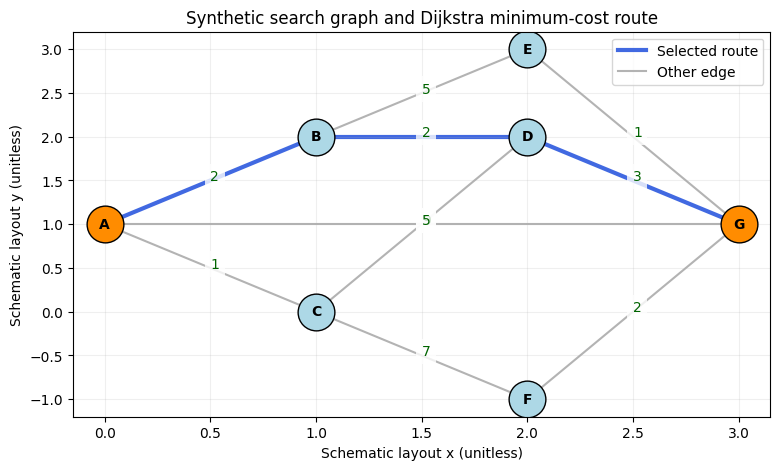

In [6]:
import matplotlib.pyplot as plt

positions = {"A": (0, 1), "B": (1, 2), "C": (1, 0), "D": (2, 2),
             "E": (2, 3), "F": (2, -1), "G": (3, 1)}
route_edges = set(zip(dijkstra_path, dijkstra_path[1:]))
fig, ax = plt.subplots(figsize=(9, 5))
drawn = set()
for node, edges in search.SAMPLE_GRAPH.items():
    for neighbor, weight in edges:
        edge = tuple(sorted((node, neighbor)))
        if edge in drawn:
            continue
        drawn.add(edge)
        x1, y1 = positions[node]
        x2, y2 = positions[neighbor]
        is_route = (node, neighbor) in route_edges or (neighbor, node) in route_edges
        ax.plot([x1, x2], [y1, y2], color="royalblue" if is_route else "0.7",
                linewidth=3 if is_route else 1.5, zorder=1)
        ax.text((x1+x2)/2, (y1+y2)/2, str(weight), color="darkgreen",
                bbox={"facecolor":"white", "alpha":0.8, "edgecolor":"none"})
for node, (x, y) in positions.items():
    color = "darkorange" if node in ("A", "G") else "lightblue"
    ax.scatter(x, y, s=700, c=color, edgecolor="black", zorder=2)
    ax.text(x, y, node, ha="center", va="center", weight="bold", zorder=3)
ax.set(title="Synthetic search graph and Dijkstra minimum-cost route",
       xlabel="Schematic layout x (unitless)", ylabel="Schematic layout y (unitless)")
ax.legend(handles=[plt.Line2D([0], [0], color="royalblue", linewidth=3, label="Selected route"),
                   plt.Line2D([0], [0], color="0.7", label="Other edge")])
ax.grid(alpha=0.2)
plt.show()

**Observation:** highlighted edges trace the minimum accumulated cost from A to G. If edge costs change, the selected route can change even though the node layout stays fixed. Layout only helps humans read connectivity; it is not part of the optimization.

## H — Debugging and common mistakes

Negative edge weights invalidate Dijkstra's assumptions. The validation below catches the invalid graph and prints the actual error.

In [7]:
bad_graph = {"A": [("B", -1.0)], "B": []}
try:
    search.dijkstra(bad_graph, "A", "B")
except ValueError as error:
    print(f"Rejected invalid graph: {error}")

print("Disconnected goal:", search.dijkstra({"A": [], "G": []}, "A", "G"))

Rejected invalid graph: edge costs must be finite and non-negative
Disconnected goal: (None, inf)


## I — Exercises

Attempt `03_Search_and_Planning_Exercises.ipynb` before opening the separate solutions notebook. Change one edge weight, predict the route, then run the search. Test a disconnected goal and an invalid heuristic.

## J — Summary and knowledge check

BFS minimizes edge count for equal-cost edges; Dijkstra minimizes nonnegative weighted cost; A* adds a remaining-cost estimate. Explain why a heuristic that overestimates can sacrifice optimality, and why a synthetic route does not authorize network changes.

**Next:** knowledge representation and reasoning, building on explicit states, goals, actions, and constraints.